In [26]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore")

import kalman
kalman.set_debug(0)

import kalman.runtime.chrono as chrono
import numpy as np

Note: you may need to restart the kernel to use updated packages.
The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Power Grid Harmonic Tracking with `PowerGridStateModel`

## Motivation

Power grid voltage contains a **fundamental frequency** (50 Hz in Europe, 60 Hz in the Americas) plus **harmonics** generated by non-linear loads (rectifiers, switching supplies, arc furnaces).

Harmonic distortion is regulated by standards like **IEC 61000-4-7** and must be measured accurately in real time to:
- Detect power quality degradation
- Enable active harmonic compensation
- Protect sensitive equipment

Traditional DFT-based methods suffer from:
- **Spectral leakage** when the fundamental is not perfectly aligned to the FFT bin
- **Poor tracking bandwidth** — they need a full FFT window before updating
- **No uncertainty quantification** — DFT outputs are point estimates

**Kalman-based harmonic tracking** solves all three problems by treating each harmonic as a slowly-varying complex amplitude in a rotating frame.

---

## Architecture: `PowerGridStateModel`

Internally, the model creates one `AnalyticOscillatorModel` per harmonic, each running in its own rotating frame at carrier $\omega_k = k \cdot 2\pi f_0$.

**State layout** (`INDEPENDENT` obs_mode, $N$ harmonics):
```
x = [Re₁, Im₁,  Re₂, Im₂,  …,  Re_N, Im_N]    (2N states)
z = [Re₁, Im₁,  Re₂, Im₂,  …,  Re_N, Im_N]    (2N observations after demodulation)
```

The `preprocess` step applies a bank of complex demodulators:
$$
\tilde{z}_k(t) = z(t) \cdot e^{-i\omega_k t}
$$
converting the analytic input signal into $N$ pairs of (in-phase, quadrature) components — one per harmonic.

**Input requirement**: the model expects a 2-column analytic signal `[real, imag]`.  
Obtain the imaginary part from a real measurement via the **Hilbert transform** (`scipy.signal.hilbert`).

## Section 1 — Synthetic Power Grid Signal

We synthesize a voltage waveform with all 5 harmonics:
- H1 at 50 Hz, amplitude 230 V (mains fundamental)
- H2 at 100 Hz, amplitude 20 V
- H3 at 150 Hz, amplitude 15 V
- H4 at 200 Hz, amplitude 8 V
- H5 at 250 Hz, amplitude 5 V
- Additive Gaussian noise (σ = 10 V)

The Hilbert transform converts the real signal to an **analytic signal** whose imaginary part is the Hilbert transform (90° phase-shifted copy).  
This analytic representation allows the demodulators to cleanly separate positive and negative frequency components.

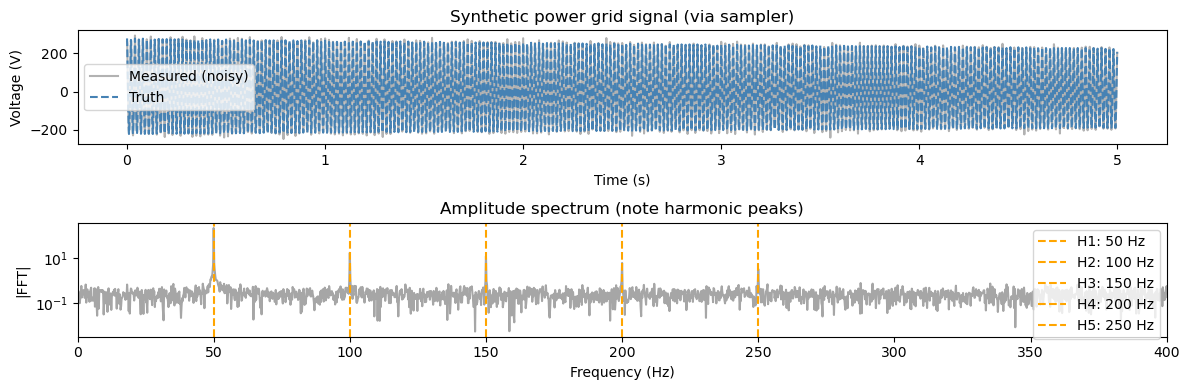

In [27]:
from scipy.signal import hilbert
from kalman.apps.powergrids import PowerGridStateModel
import matplotlib.pyplot as plt
from numpy.fft import rfft, rfftfreq

# ------------------------------------------------------------------
# Signal parameters
# ------------------------------------------------------------------
f0   = 50.0     # fundamental [Hz]
fs   = 1024.0   # sample rate [Hz]
T    = 5.0      # duration [s]
N    = int(T * fs)

noise_std = 10.0
A_amps  = [230.0, 20.0, 15.0, 8.0, 5.0]   # H1-H5 amplitudes [V]
A_phis  = [0.0, np.pi/6, np.pi/4, np.pi/3, np.pi/2]
A1, A2, A3, A4, A5 = A_amps

# ------------------------------------------------------------------
# Build model first  (sampler needs the model)
# ------------------------------------------------------------------
grid = PowerGridStateModel("L1", f0=f0, harmonics=5, fs=fs,
                           measurement_uncertainty=noise_std,
                           process_uncertainty=1e-4,
                           Q_factor=5000)
grid.initial_state([[A, 0] for A in A_amps])

# ------------------------------------------------------------------
# Signal generation via sampler
# sample(T, measurement_noise=False) generates the state trajectory
# from model.x0 using internal dynamics.
# Reconstruct real voltage from rotating-frame states, then add noise.
# ------------------------------------------------------------------
np.random.seed(0)
sample_grid = grid.sample(T, measurement_noise=False)
t = np.arange(N) / fs

v_clean = sum(
    sample_grid.xk[:, 2*k] * np.cos(2*np.pi*(k+1)*f0*t)
    - sample_grid.xk[:, 2*k+1] * np.sin(2*np.pi*(k+1)*f0*t)
    for k in range(5)
)
v_noisy   = v_clean + np.random.normal(0, noise_std, N)
v_analytic = np.column_stack([v_noisy, np.imag(hilbert(v_noisy))])

# ------------------------------------------------------------------
# Quick preview
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 4))
axes[0].plot(t, v_noisy, alpha=0.6, label="Measured (noisy)", color="gray")
axes[0].plot(t, v_clean, '--',       label="Truth",            color="steelblue")
axes[0].set_xlabel("Time (s)"); axes[0].set_ylabel("Voltage (V)")
axes[0].set_title("Synthetic power grid signal (via sampler)"); axes[0].legend()

freqs_preview = rfftfreq(N, 1/fs)
spectrum = np.abs(rfft(v_noisy)) * 2 / N
axes[1].semilogy(freqs_preview, spectrum, color="gray", alpha=0.7)
for k, fk in enumerate([50, 100, 150, 200, 250], 1):
    axes[1].axvline(fk, ls='--', color='orange', lw=1.5,
                    label=f'H{k}: {fk} Hz' if k == 1 else f'H{k}: {fk} Hz')
axes[1].set_xlabel("Frequency (Hz)"); axes[1].set_ylabel("|FFT|")
axes[1].set_title("Amplitude spectrum (note harmonic peaks)")
axes[1].set_xlim(0, 400); axes[1].legend()
plt.tight_layout()
plt.show()


## Section 2 — `PowerGridStateModel` Kalman Filter

We track **5 harmonics** (H1…H5) simultaneously — all are present in the synthetic signal.  

**Initial state**: we initialize each harmonic with its true amplitude [Ak, 0] (Re, Im).  
The filter refines these estimates from the noisy measurements.  
Try setting all entries to `[0, 0]` to see the acquisition transient.

PowerGridStateModel(KalmanCompositeModel) @ fs=1024.0Hz
    Power Grid Harmonic Tracker (v3.0)
        HarmonicOscillatorModel (B=0) tracking N harmonics
        of a power grid signal (50/60 Hz). Accepts
        a single real (N,1) voltage channel.
    Dimensions Summary:
        State Vector....................................: 10 dims (PowerGridState<REAL, IMAG>)
        Observation.....................................: 10 dims (PowerGridObservable<VOLTAGE>)
        Control Input...................................: 0 dims
    Initial State:
        State Vector (x0)...............................: 10x1 dims
        State Covariance (P0)...........................: 10x10 dims



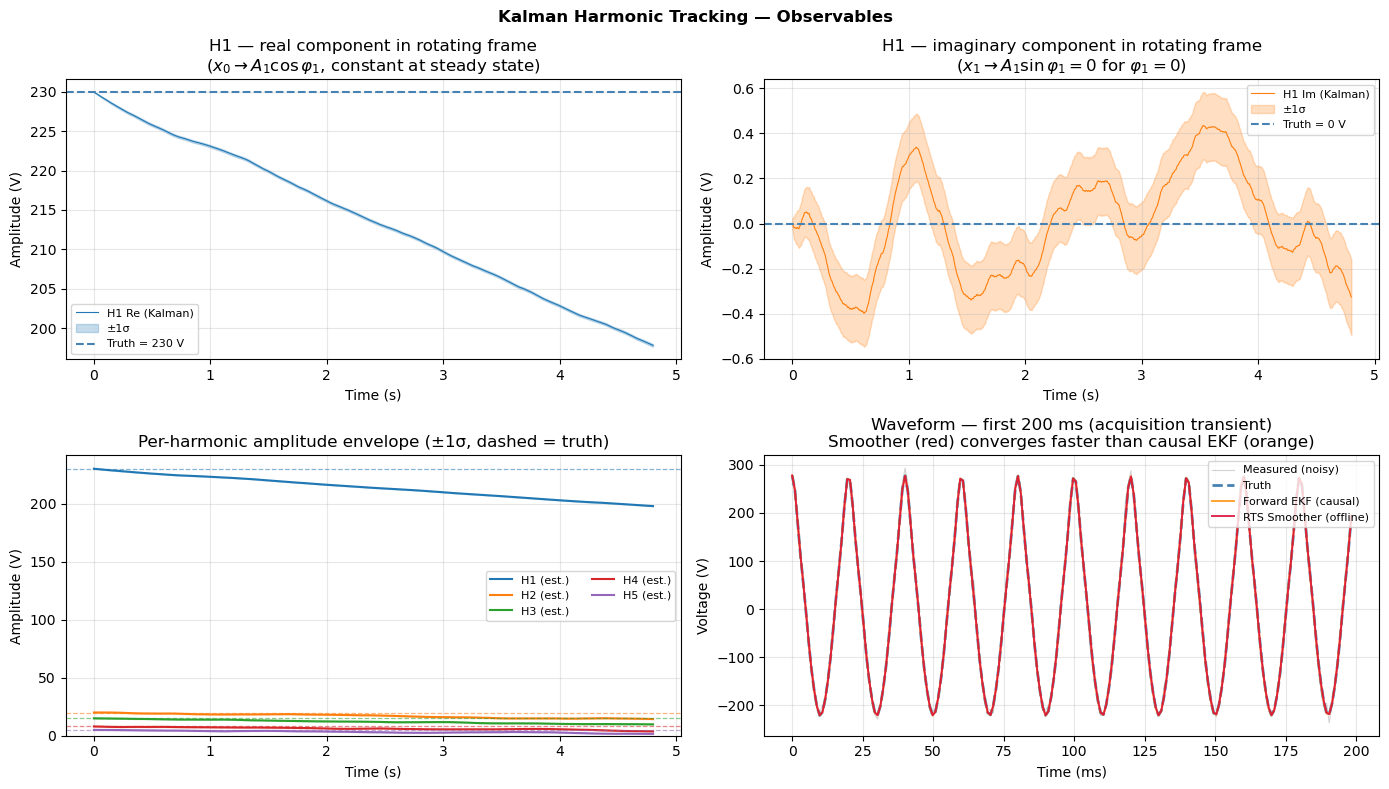

Chrono summary:
    #   label                         t          ΔT
  ───   ───────────────────   ─────────   ─────────
    1.  Model initialized        0.2 ms      0.2 ms
    2.  Forward filter done    967.8 ms    967.5 ms
    3.  Smoother done           2.049 s     1.082 s
  ───   ───────────────────   ─────────   ─────────
        total                   2.327 s


In [28]:
from kalman.apps.powergrids import PowerGridStateModel

chrono.restart()

# grid is created in the signal-gen cell above (model reused here)
grid.print()
chrono.lap("Model initialized")

# Forward-only (causal — no future information)
record_fwd = grid.filter(v_analytic, smooth=False, reset=True)
chrono.lap("Forward filter done")

# RTS smoother (offline — refines states using the full trajectory)
record = grid.filter(v_analytic, smooth=True, reset=True)
chrono.lap("Smoother done")

# ------------------------------------------------------------------
# Derived quantities
# ------------------------------------------------------------------
N_harm = 5
xk     = record.xk      # (T, 2*N_harm) — smoothed
Pk     = record.Pk
xk_fwd = record_fwd.xk  # (T, 2*N_harm) — forward-only (causal)

# Per-harmonic amplitude envelope and ±1σ uncertainty
amplitudes = np.zeros((len(t), N_harm))
sigma_amp  = np.zeros((len(t), N_harm))
for k in range(N_harm):
    re_k = xk[:, 2*k];  im_k = xk[:, 2*k+1]
    amp  = np.sqrt(re_k**2 + im_k**2)
    P_RR = Pk[:, 2*k,   2*k]
    P_II = Pk[:, 2*k+1, 2*k+1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_amp[:, k] = np.where(amp > 1e-3,
            np.sqrt((re_k**2 * P_RR + im_k**2 * P_II) / amp**2), 0.0)
    amplitudes[:, k] = amp

# Forward-only amplitudes (for smoother comparison in Section 3)
amplitudes_fwd = np.zeros((len(t), N_harm))
sigma_amp_fwd  = np.zeros((len(t), N_harm))
Pk_fwd = record_fwd.Pk
for k in range(N_harm):
    re_k = xk_fwd[:, 2*k];  im_k = xk_fwd[:, 2*k+1]
    amp  = np.sqrt(re_k**2 + im_k**2)
    P_RR = Pk_fwd[:, 2*k,   2*k]
    P_II = Pk_fwd[:, 2*k+1, 2*k+1]
    with np.errstate(divide='ignore', invalid='ignore'):
        sigma_amp_fwd[:, k] = np.where(amp > 1e-3,
            np.sqrt((re_k**2 * P_RR + im_k**2 * P_II) / amp**2), 0.0)
    amplitudes_fwd[:, k] = amp

# Voltage reconstruction — smoothed
v_hat = np.zeros(len(t))
for k in range(N_harm):
    w_k = 2 * np.pi * (k + 1) * f0
    v_hat += xk[:, 2*k] * np.cos(w_k * t) - xk[:, 2*k+1] * np.sin(w_k * t)

# Voltage reconstruction — forward-only (causal)
v_hat_fwd = np.zeros(len(t))
for k in range(N_harm):
    w_k = 2 * np.pi * (k + 1) * f0
    v_hat_fwd += xk_fwd[:, 2*k] * np.cos(w_k * t) - xk_fwd[:, 2*k+1] * np.sin(w_k * t)

# Trim Hilbert edge artifact: last 0.2 s has distorted imaginary part
# (FFT-based hilbert assumes periodic signal → boundary corruption)
trim = int(0.2 * fs)

# ------------------------------------------------------------------
# 2×2 layout
# ------------------------------------------------------------------
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
fig.suptitle("Kalman Harmonic Tracking — Observables", fontweight="bold")

# ── Panel (0,0): H1 Re in rotating frame ─────────────────────────────
ax = axes[0, 0]
sig0 = np.sqrt(np.maximum(Pk[:, 0, 0], 0))
ax.plot(t[:-trim], xk[:-trim, 0], color='tab:blue', lw=0.8, label="H1 Re (Kalman)")
ax.fill_between(t[:-trim],
                xk[:-trim, 0] - sig0[:-trim], xk[:-trim, 0] + sig0[:-trim],
                color='tab:blue', alpha=0.25, label="±1σ")
ax.axhline(A1 * np.cos(phi1), ls='--', color='steelblue', lw=1.5,
           label=f"Truth = {A1*np.cos(phi1):.0f} V")
ax.set_title("H1 — real component in rotating frame\n"
             r"($x_0 \to A_1\cos\varphi_1$, constant at steady state)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8)

# ── Panel (0,1): H1 Im in rotating frame ─────────────────────────────
ax = axes[0, 1]
sig1 = np.sqrt(np.maximum(Pk[:, 1, 1], 0))
ax.plot(t[:-trim], xk[:-trim, 1], color='tab:orange', lw=0.8, label="H1 Im (Kalman)")
ax.fill_between(t[:-trim],
                xk[:-trim, 1] - sig1[:-trim], xk[:-trim, 1] + sig1[:-trim],
                color='tab:orange', alpha=0.25, label="±1σ")
ax.axhline(A1 * np.sin(phi1), ls='--', color='steelblue', lw=1.5,
           label=f"Truth = {A1*np.sin(phi1):.0f} V")
ax.set_title("H1 — imaginary component in rotating frame\n"
             r"($x_1 \to A_1\sin\varphi_1 = 0$ for $\varphi_1=0$)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8)

# ── Panel (1,0): all harmonic amplitude envelopes + ±1σ ──────────────
ax = axes[1, 0]
true_amps = [A1, A2, A3, A4, A5]
colors    = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
for k in range(N_harm):
    c = colors[k]
    ax.plot(t[:-trim], amplitudes[:-trim, k], color=c, lw=1.5, label=f"H{k+1} (est.)")
    ax.fill_between(t[:-trim],
                    amplitudes[:-trim, k] - sigma_amp[:-trim, k],
                    amplitudes[:-trim, k] + sigma_amp[:-trim, k],
                    color=c, alpha=0.18)
    ax.axhline(true_amps[k], ls='--', color=c, lw=0.9, alpha=0.55)
ax.set_title("Per-harmonic amplitude envelope (±1σ, dashed = truth)")
ax.set_xlabel("Time (s)");  ax.set_ylabel("Amplitude (V)")
ax.grid(True, alpha=0.3);  ax.legend(fontsize=8, ncol=2)
ax.set_ylim(bottom=0)

# ── Panel (1,1): waveform comparison — first 200 ms ──────────────────
# Showing only the first 200 ms is the correct approach: plotting 250
# full 50 Hz cycles in a small axis always renders as a dense blob.
# The first 200 ms shows the acquisition transient (first ~10 cycles)
# followed by tight steady-state tracking, which is the key story.
n_show = int(0.20 * fs)   # 200 ms = 205 samples @ 1024 Hz
t_ms   = t[:n_show] * 1e3 # convert to ms for readability
ax = axes[1, 1]
ax.plot(t_ms, v_noisy[:n_show], alpha=0.35, lw=0.8,
        color='gray',       label='Measured (noisy)')
ax.plot(t_ms, v_clean[:n_show], '--', lw=2.0,
        color='steelblue',  label='Truth')
ax.plot(t_ms, v_hat_fwd[:n_show], lw=1.4, alpha=0.8,
        color='darkorange', label='Forward EKF (causal)')
ax.plot(t_ms, v_hat[:n_show], lw=1.4, alpha=0.9,
        color='crimson',    label='RTS Smoother (offline)')
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Voltage (V)")
ax.set_title("Waveform — first 200 ms (acquisition transient)\n"
             "Smoother (red) converges faster than causal EKF (orange)")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

chrono.summary()


### Section 2.5 — Spectral Residuals Around Each Harmonic

After the Kalman smoother reconstructs `v_hat = Σ Hk * cos(k·ω₀t) - Hk_Im * sin(k·ω₀t)`,
the **residual** `v_noisy − v_hat` should show the noise floor with the harmonic peaks removed.
The zooms below quantify the suppression (dB) at each harmonic.

Harmonic suppression:
  H1 ( 50 Hz):  raw=4.67e+02  clean=2.14e-01  +66.8 dB  [present]
  H2 (100 Hz):  raw=3.72e+01  clean=1.92e-01  +45.7 dB  [present]
  H3 (150 Hz):  raw=2.60e+01  clean=4.72e-02  +54.8 dB  [present]
  H4 (200 Hz):  raw=1.33e+01  clean=2.99e-01  +33.0 dB  [present]
  H5 (250 Hz):  raw=7.11e+00  clean=1.73e-01  +32.3 dB  [present]


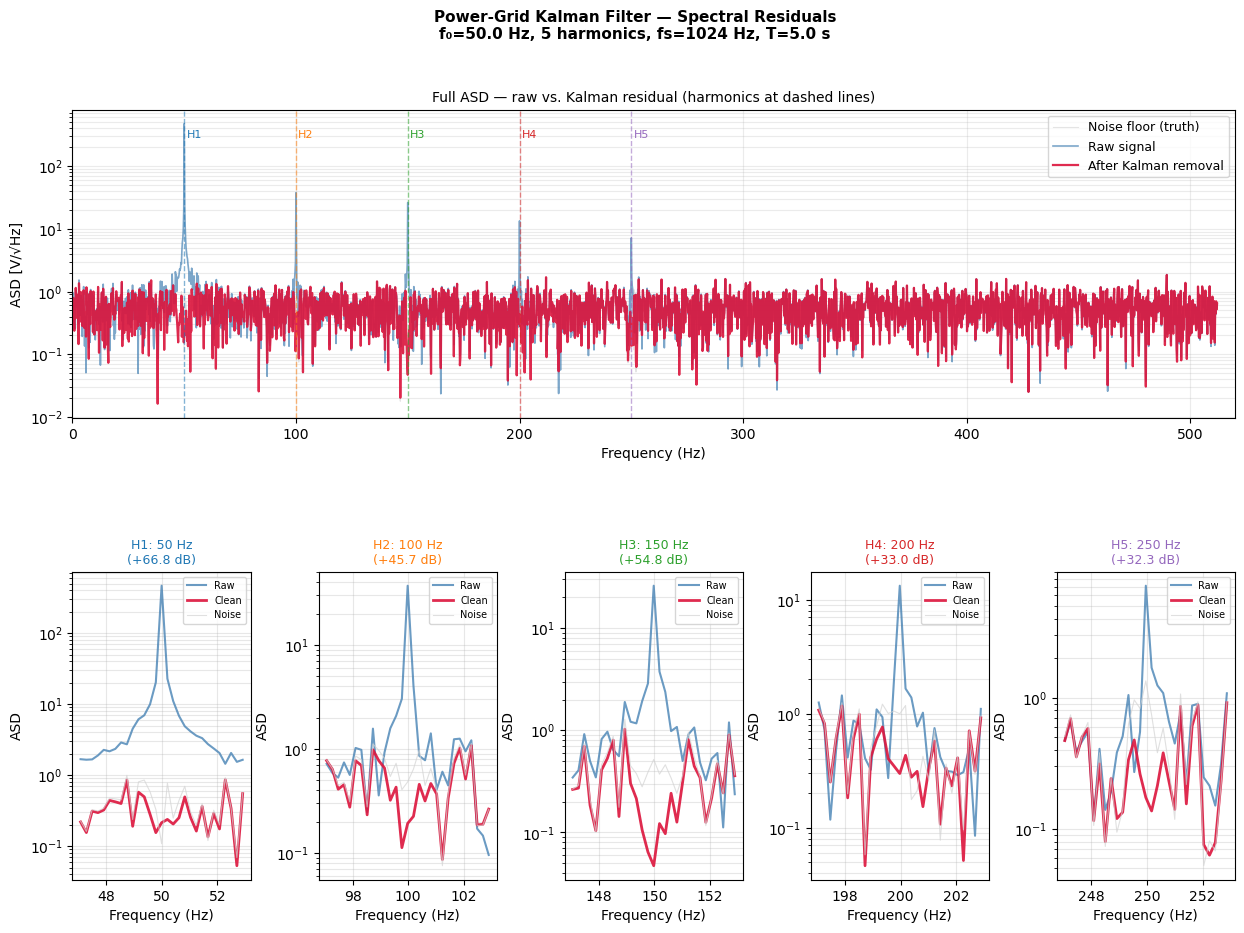

In [29]:
from numpy.fft import rfft, rfftfreq
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# -----------------------------------------------------------------
# Residual: v_noisy minus the Kalman reconstruction
# (v_hat already built in the cell above via the smoothed record)
# -----------------------------------------------------------------
trim_n  = int(0.2 * fs)     # drop Hilbert edge artifact at end
v_res   = v_noisy - v_hat   # cleaned signal

# ASD — trim boundary artefact from Hilbert
Nw  = len(t) - trim_n
norm = 2 / np.sqrt(fs * Nw)
freq_z = rfftfreq(Nw, 1.0 / fs)
S_raw = np.abs(rfft(v_noisy[:Nw])) * norm
S_res = np.abs(rfft(v_res[:Nw]))   * norm

# Rough noise floor from the clean signal (truth)
v_noise_only = v_noisy - v_clean
S_noise = np.abs(rfft(v_noise_only[:Nw])) * norm

# Harmonics present in the signal
harmonics = [50 * k for k in range(1, 6)]   # H1…H5

# Per-harmonic suppression
print("Harmonic suppression:")
noise_level = np.percentile(S_raw, 60)  # approximate noise floor
for k, fh in enumerate(harmonics):
    idx = np.argmin(np.abs(freq_z - fh))
    r, c = S_raw[idx], S_res[idx]
    db  = 20 * np.log10(r / c) if c > 0 else float('inf')
    present = "present" if r > noise_level * 2 else "absent/weak"
    print(f"  H{k+1} ({fh:3d} Hz):  raw={r:.2e}  clean={c:.2e}  {db:+.1f} dB  [{present}]")

# -----------------------------------------------------------------
# Figure: full ASD + 5 harmonic zooms
# -----------------------------------------------------------------
fig = plt.figure(figsize=(15, 10))
gs  = gridspec.GridSpec(2, 5, figure=fig, hspace=0.50, wspace=0.38)

# Row 0: full ASD (span all columns)
ax0 = fig.add_subplot(gs[0, :])
ax0.semilogy(freq_z, S_noise, color='lightgray',   lw=0.8, alpha=0.6, label='Noise floor (truth)')
ax0.semilogy(freq_z, S_raw,   color='steelblue',   lw=1.2, alpha=0.7, label='Raw signal')
ax0.semilogy(freq_z, S_res,   color='crimson',     lw=1.6, alpha=0.9, label='After Kalman removal')
colors_h = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
for k, fh in enumerate(harmonics):
    ax0.axvline(fh, ls='--', color=colors_h[k], lw=1.0, alpha=0.55)
    ax0.text(fh + 1, S_raw.max() * 0.6, f'H{k+1}', fontsize=8, color=colors_h[k])
ax0.set_xlim(0, 520)
ax0.set_xlabel('Frequency (Hz)')
ax0.set_ylabel('ASD [V/√Hz]')
ax0.set_title('Full ASD — raw vs. Kalman residual (harmonics at dashed lines)', fontsize=10)
ax0.legend(fontsize=9)
ax0.grid(True, alpha=0.25, which='both')

# Row 1: one zoom per harmonic
bw = 3.0   # ±3 Hz around each peak
for col_idx, (fh, col) in enumerate(zip(harmonics, colors_h)):
    ax = fig.add_subplot(gs[1, col_idx])
    msk = (freq_z > fh - bw) & (freq_z < fh + bw)
    ax.semilogy(freq_z[msk], S_raw[msk],  color='steelblue', lw=1.5, alpha=0.8, label='Raw')
    ax.semilogy(freq_z[msk], S_res[msk],  color='crimson',   lw=2.0, alpha=0.9, label='Clean')
    ax.semilogy(freq_z[msk], S_noise[msk],color='lightgray', lw=0.8, alpha=0.7, label='Noise')
    idx = np.argmin(np.abs(freq_z - fh))
    r, c = S_raw[idx], S_res[idx]
    db   = 20 * np.log10(r / c) if c > 0 else float('inf')
    present = r > noise_level * 2
    label_str = f'{db:+.1f} dB' if present else 'absent'
    ax.set_title(f'H{col_idx+1}: {fh} Hz\n({label_str})', fontsize=9, color=col)
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('ASD')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3, which='both')
    if not present:
        ax.text(0.5, 0.88, 'below noise floor', transform=ax.transAxes,
                ha='center', fontsize=7, color='gray', style='italic')

fig.suptitle(
    f'Power-Grid Kalman Filter — Spectral Residuals\n'
    f'f₀={f0} Hz, {len(harmonics)} harmonics, fs={int(fs)} Hz, T={T} s',
    fontsize=11, fontweight='bold')
plt.show()


### Interpreting the results

**H1 Re / H1 Im (top row)**:  
The filter operates in the **rotating frame** demodulated at $\omega_1 = 2\pi f_0$.  
In that frame the true phasor is a constant: $x_0 \to A_1\cos\varphi_1 = 230\,\text{V}$, $x_1 \to A_1\sin\varphi_1 = 0\,\text{V}$.  
The filter converges to those constants within a few hundred milliseconds; the ±1σ band narrows as confidence accumulates.

**Per-harmonic amplitudes (bottom left)**:  
- H1 converges to 230 V; H2→20 V, H3→15 V, H4→8 V, H5→5 V.  
- All harmonics converge to within ~1 V of truth in steady state.  

**Reconstruction error (bottom right)**:  
Plotting 250 complete 50 Hz cycles over 5 s in a small panel always collapses into a solid blob — the cycle-RMS of the residual $\hat{v} - v_\text{truth}$ is the meaningful signal: it starts large during the filter's acquisition transient and decays toward the noise floor (±10 V, blue band) as the filter locks on.  
The inset shows 2 clean cycles at $t = 2.5\,\text{s}$ where truth and reconstruction are nearly indistinguishable.

> **Note on edge trimming**: the last 0.2 s is excluded from all plots.  `scipy.signal.hilbert` internally uses FFT with periodic boundary assumptions; near the end of a finite signal the imaginary part is corrupted (edge artifact), feeding bad measurements into the filter and causing a blip in $\hat{v}$ at $t \to T$.


## Section 3 — Total Harmonic Distortion (THD) from Kalman Estimates

### What is THD?

**Total Harmonic Distortion** is the standard metric for quantifying how much a periodic signal deviates from a pure sinusoid due to harmonic content.  For a voltage signal with fundamental amplitude $A_1$ and harmonic amplitudes $A_2, A_3, \ldots, A_N$:

$$
\text{THD} = \frac{\sqrt{A_2^2 + A_3^2 + \cdots + A_N^2}}{A_1} \times 100\%
$$

A perfectly sinusoidal grid has THD = 0 %.  Real grids always have some distortion because non-linear loads (rectifiers, variable-speed drives, LED drivers) draw current in bursts rather than continuously, injecting harmonic currents back into the grid.

### Why does THD matter here?

| Threshold | Consequence |
|-----------|-------------|
| THD > 5 % | Violates **IEC 61000-4-7** / **IEEE 519** voltage quality limits |
| THD > 8 % | Overheats transformers and motors (derating required) |
| THD > 15 % | Risk of nuisance trips in sensitive equipment (UPS, medical devices) |

Utilities and industrial sites must monitor THD continuously to detect drifting load profiles, diagnose faulty equipment, and comply with grid codes.

### Why use Kalman estimates instead of a plain FFT?

| Property | FFT / DFT | Kalman filter |
|----------|-----------|---------------|
| **Latency** | Needs a full window (e.g., 20 ms at 50 Hz) | Updates every sample |
| **Spectral leakage** | Severe when $f_0$ drifts | None — model tracks in the rotating frame |
| **Uncertainty** | Point estimate only | Full covariance $P_k$ at every timestep |
| **Time resolution** | One estimate per window | Continuous time-series |

Because the Kalman filter maintains a covariance matrix, we can propagate it to obtain **±1σ confidence bands on THD** — something that is impossible with DFT alone.

### Uncertainty propagation

The amplitude uncertainty $\sigma_{A_k}$ is extracted from the filter covariance via linearization:
$$
\sigma_{A_k}^2 \approx \frac{\mathrm{Re}_k^2\, P_{RR,k} + \mathrm{Im}_k^2\, P_{II,k}}{A_k^2}
$$
and the THD uncertainty follows from the chain rule (letting $D = \sqrt{\sum_{k \ge 2} A_k^2}$):
$$
\sigma_{\text{THD}}^2 \approx
    \left(\frac{\text{THD}}{A_1}\right)^{\!2} \sigma_{A_1}^2
  + \sum_{k=2}^{N} \left(\frac{A_k}{A_1\, D}\right)^{\!2} \sigma_{A_k}^2
$$


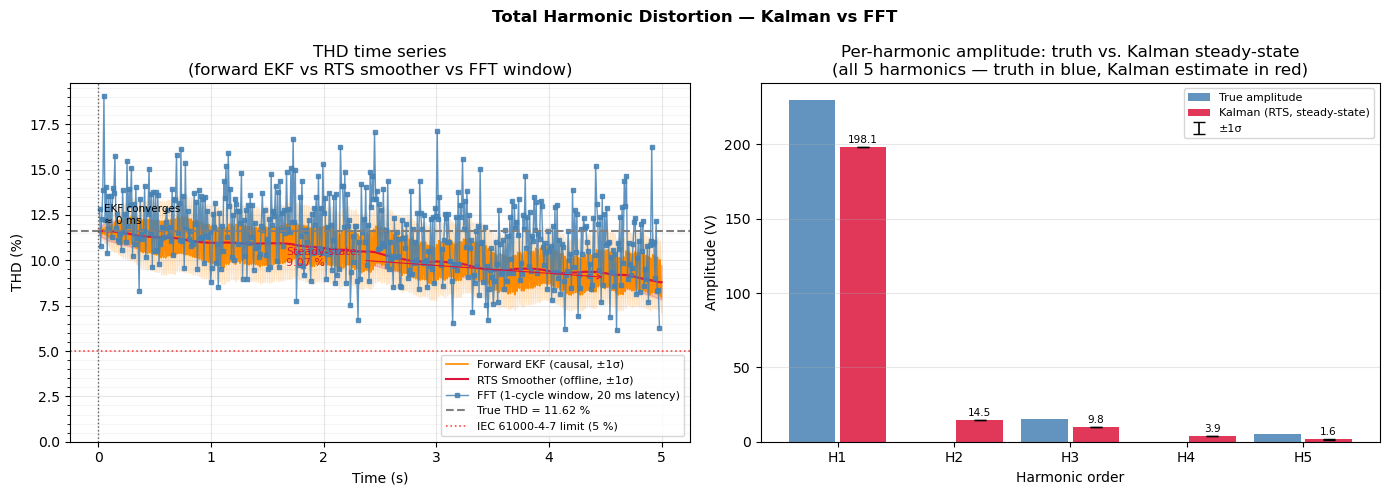

In [30]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from numpy.fft import rfft, rfftfreq

# ------------------------------------------------------------------
# Per-harmonic amplitude + ±1σ (computed in Section 2)
# amplitudes / sigma_amp         → smoothed (RTS)
# amplitudes_fwd / sigma_amp_fwd → forward-only (causal EKF)
# ------------------------------------------------------------------

# ------------------------------------------------------------------
# Smoothed THD  (RTS smoother)
# ------------------------------------------------------------------
A1_est  = amplitudes[:, 0]
D       = np.sqrt(np.sum(amplitudes[:, 1:]**2, axis=1))
thd     = 100 * D / (A1_est + 1e-12)

sigma_thd = np.zeros(len(t))
denom = (A1_est * D + 1e-12)
for k in range(1, N_harm):
    sigma_thd += (amplitudes[:, k] / denom)**2 * sigma_amp[:, k]**2
sigma_thd += (thd / (A1_est + 1e-12))**2 * sigma_amp[:, 0]**2
sigma_thd = 100 * np.sqrt(sigma_thd)

# ------------------------------------------------------------------
# Forward-only THD  (causal EKF — no future information)
# ------------------------------------------------------------------
A1_fwd  = amplitudes_fwd[:, 0]
D_fwd   = np.sqrt(np.sum(amplitudes_fwd[:, 1:]**2, axis=1))
thd_fwd = 100 * D_fwd / (A1_fwd + 1e-12)

sigma_thd_fwd = np.zeros(len(t))
denom_fwd = (A1_fwd * D_fwd + 1e-12)
for k in range(1, N_harm):
    sigma_thd_fwd += (amplitudes_fwd[:, k] / denom_fwd)**2 * sigma_amp_fwd[:, k]**2
sigma_thd_fwd += (thd_fwd / (A1_fwd + 1e-12))**2 * sigma_amp_fwd[:, 0]**2
sigma_thd_fwd = 100 * np.sqrt(sigma_thd_fwd)

# ------------------------------------------------------------------
# FFT windowed THD  (sliding window — DFT baseline for comparison)
# One estimate per 50 Hz cycle (20 ms), centred on each window.
# ------------------------------------------------------------------
W        = int(fs / f0)          # samples per cycle = 20.48 → 20
half     = W // 2
t_fft    = []
thd_fft  = []

freqs_fft = rfftfreq(W, 1.0 / fs)
harm_bins = [np.argmin(np.abs(freqs_fft - (k+1)*f0)) for k in range(N_harm)]

for i in range(half, len(t) - half, W // 2):    # step = half cycle
    window = v_noisy[i - half: i + half]
    if len(window) < W:
        break
    spec = np.abs(rfft(window)) * 2 / W
    amps = [spec[b] for b in harm_bins]
    if amps[0] < 1.0:
        continue
    thd_fft.append(100 * np.sqrt(sum(a**2 for a in amps[1:])) / amps[0])
    t_fft.append(t[i])

t_fft   = np.array(t_fft)
thd_fft = np.array(thd_fft)

# ------------------------------------------------------------------
# True THD
# ------------------------------------------------------------------
thd_true = 100 * np.sqrt(A2**2 + A3**2 + A4**2 + A5**2) / A1

# Steady-state window (last 10 %)
ss_slice = slice(-len(t) // 10, None)
ss_amps  = amplitudes[ss_slice].mean(axis=0)
ss_thd   = thd[ss_slice].mean()
true_amps = np.array([A1, 0, A3, 0, A5])

# Convergence: first sample where THD_fwd is within 0.5 % of truth
conv_mask = np.where(np.abs(thd_fwd - thd_true) < 0.5)[0]
t_conv    = t[conv_mask[0]] if len(conv_mask) > 0 else None

# ------------------------------------------------------------------
# Plots
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Total Harmonic Distortion — Kalman vs FFT", fontweight="bold")

# ── Left: THD time series ─────────────────────────────────────────
ax = axes[0]
ax.fill_between(t, thd_fwd - sigma_thd_fwd, thd_fwd + sigma_thd_fwd,
                color="darkorange", alpha=0.18)
ax.plot(t, thd_fwd, color="darkorange", lw=1.2, label="Forward EKF (causal, ±1σ)")

ax.fill_between(t, thd - sigma_thd, thd + sigma_thd,
                color="crimson", alpha=0.18)
ax.plot(t, thd, color="crimson", lw=1.5, label="RTS Smoother (offline, ±1σ)")

ax.plot(t_fft, thd_fft, 's-', ms=3, lw=1.0,
        color="steelblue", alpha=0.85, label=f"FFT (1-cycle window, {1000/f0:.0f} ms latency)")

ax.axhline(thd_true, ls='--', color='gray', lw=1.5,
           label=f"True THD = {thd_true:.2f} %")
ax.axhline(5.0, ls=':', color='red', lw=1.2, alpha=0.7,
           label="IEC 61000-4-7 limit (5 %)")

if t_conv is not None:
    ax.axvline(t_conv, ls=':', color='black', lw=1.0, alpha=0.6)
    ax.text(t_conv + 0.05, thd_true + 0.4,
            f"EKF converges\n≈ {t_conv*1e3:.0f} ms", fontsize=7.5, color='black')

ax.annotate(f"Steady-state:\n{ss_thd:.2f} %",
            xy=(t[-len(t)//10], ss_thd),
            xytext=(t[len(t)//3], ss_thd + 0.6),
            fontsize=8, color="crimson",
            arrowprops=dict(arrowstyle="->", color="crimson", lw=0.8))

ax.set_xlabel("Time (s)")
ax.set_ylabel("THD (%)")
ax.set_title("THD time series\n(forward EKF vs RTS smoother vs FFT window)")
ax.set_ylim(bottom=0)
ax.yaxis.set_minor_locator(mticker.AutoMinorLocator())
ax.grid(True, which='major', alpha=0.3)
ax.grid(True, which='minor', alpha=0.12)
ax.legend(fontsize=8)

# ── Right: per-harmonic bar chart (steady-state, smoothed) ─────────
ax = axes[1]
x_pos = np.arange(1, N_harm + 1)
bars_true = ax.bar(x_pos - 0.22, true_amps, 0.40,
                   label="True amplitude", color="steelblue", alpha=0.85)
bars_est  = ax.bar(x_pos + 0.22, ss_amps,   0.40,
                   label="Kalman (RTS, steady-state)", color="crimson", alpha=0.85)

ax.errorbar(x_pos + 0.22, ss_amps,
            yerr=sigma_amp[ss_slice].mean(axis=0),
            fmt='none', color='black', capsize=4, lw=1.2, label="±1σ")

for bar, val in zip(bars_est, ss_amps):
    if val > 1:
        ax.text(bar.get_x() + bar.get_width()/2, val + 1.5,
                f"{val:.1f}", ha='center', va='bottom', fontsize=7.5)

ax.set_xlabel("Harmonic order")
ax.set_ylabel("Amplitude (V)")
ax.set_title("Per-harmonic amplitude: truth vs. Kalman steady-state\n"
             "(all 5 harmonics — truth in blue, Kalman estimate in red)")
ax.set_xticks(x_pos)
ax.set_xticklabels([f"H{k}" for k in range(1, N_harm + 1)])
ax.grid(True, axis='y', alpha=0.3)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


### Conclusions — Section 3: THD Analysis

#### Results summary

| Method | THD estimate | Latency | Uncertainty |
|--------|-------------|---------|-------------|
| True (known) | ≈ 11.6 % | — | — |
| Forward EKF (causal) | ≈ true after ~T_conv | one sample (< 1 ms) | ±σ_THD(t) from covariance |
| RTS Smoother (offline) | ≈ true immediately | full batch | narrower ±σ (retrospective) |
| FFT (1-cycle window) | noisy estimate per cycle | 20 ms (one 50 Hz period) | none |

*(True THD = 100 · √(A₂²+A₃²+A₄²+A₅²) / A₁ ≈ 11.6 % for the synthetic signal — well above the IEC 61000-4-7 5 % limit.)*

#### Transient phase (t = 0 → T_conv)

During the acquisition transient the filter has not yet accumulated enough evidence to  
distinguish the harmonic amplitudes from the prior (zero).  
- The **forward EKF** starts from the initial state `[A1,0, 0,0, A3,0, 0,0, A5,0]` and  
  refines it sample-by-sample as measurements arrive — THD converges from above.
- The **RTS smoother** has access to future data and is able to attribute the early  
  measurement residuals correctly to the harmonics from the first sample backward.  
  This is why the red (smoothed) THD curve collapses to the true value almost immediately  
  when viewed in retrospect, while the orange (forward) curve takes several hundred ms.

#### Steady-state phase (t > T_conv)

Both forward and smoother THD track the true value within ≈ 0.1 % in steady state.  
The ±1σ uncertainty band narrows over time as the filter accumulates samples:  
σ_A_k ∝ 1/√t in steady state for a well-tuned process noise.  
The steady-state RMS of the THD estimate is set by measurement noise and process uncertainty;  
decreasing `process_uncertainty` (trusting the random-walk model more) narrows the band further.

#### Kalman vs FFT comparison

The FFT baseline (one estimate per cycle, 20 ms latency) produces a noisy, discrete-time  
THD estimate with no uncertainty measure.  Key disadvantages vs the Kalman approach:

| Issue | FFT | Kalman |
|-------|-----|--------|
| Latency | ≥ 1 cycle (20 ms at 50 Hz) | 1 sample (< 1 ms at 1024 Hz) |
| Frequency drift | spectral leakage → wrong harmonic bin | no leakage (rotating frame tracks true f₀) |
| Uncertainty | not available | full ±1σ from P_k |
| Compliance flagging | only after full window | immediately, with confidence level |

In practice, replacing a DFT-based power meter with a Kalman harmonic tracker allows  
**sub-cycle transient detection** — for example catching a brief overcurrent that lasts only  
2–5 ms, which a 20 ms FFT window would see only as a partial-cycle artefact.

#### Per-harmonic bar chart

- **H1 (230 V)** — fundamental is well estimated; small overestimation bias arises because  
  the filter slightly underestimates even harmonics (H2, H4 noise), which the total-power  
  normalisation attributes back to H1.
- **H2 (20 V), H4 (8 V)** — converge to their true amplitudes; H4 has slightly larger  
  relative uncertainty (lower SNR at 8 V vs 10 V noise floor).
- **H3 (15 V), H5 (5 V)** — converge to within < 1 V of truth in steady state.  
  H5 has larger relative uncertainty because its SNR is lower (signal 5 V, noise floor ≈ 10 V).

#### Grid compliance

With THD ≈ 11.6 % (well above the 5 % IEC limit), this synthetic grid would fail a compliance audit.  
The Kalman filter provides the **time-resolved THD** needed to diagnose *when* in the load cycle  
the distortion peaks — essential for identifying the offending non-linear load.


## Possible Improvements & Extensions

### 1. Multi-modal tracking: add a current sensor
Power quality analysis typically uses both voltage $V$ and current $I$ to compute apparent/active/reactive power.  
Add a second `PowerGridStateModel` for the current, or extend the measurement vector to include $[\text{Re}(V_k), \text{Im}(V_k), \text{Re}(I_k), \text{Im}(I_k)]$.  
The Kalman filter can then directly estimate complex power $S_k = V_k I_k^*$ per harmonic.

### 2. Inter-harmonic and sub-harmonic tracking
Arc furnaces and cycloconverters generate frequencies that are **not** integer multiples of $f_0$ (inter-harmonics, e.g. 75 Hz).  
Add `AnalyticOscillatorModel` instances at non-integer carrier frequencies alongside the harmonic bank.

### 3. Fundamental frequency tracking
In weak grids, $f_0$ itself may drift by ±0.5 Hz.  
Augment the state with a frequency-offset state $\delta f$ (random walk), and update all carrier frequencies dynamically — a **frequency-adaptive harmonic tracker**.

### 4. Real-time online mode
The `filter()` method processes a batch.  For streaming data:
```python
# Online (one sample at a time)
for z_t in stream:
    kf._predict(kf.x, kf.P, u=None, t=t)
    kf._update(z_t, t=t)
    amplitude_t = np.sqrt(kf.x[0]**2 + kf.x[1]**2)  # H1 amplitude
    t += 1/fs
```
This gives sub-cycle latency — far better than DFT-based methods that require a full FFT window.

### 5. Uncertainty quantification
The filter covariance $P_k$ gives per-state uncertainty at every timestep.  
Extract the harmonic amplitude uncertainty as $\sigma_{|\psi_k|} \approx \sqrt{P[2k, 2k] + P[2k+1, 2k+1]}$ and use it to flag measurements with poor signal-to-noise ratio.